# Quantum optical reservoir computing for tabular network data

Inspired by the work of [Sakurai et al.](https://opg.optica.org/opticaq/abstract.cfm?URI=opticaq-3-3-238),
this tutorial applies **Quantum Optical Reservoir Computing (QORC)** to tabular network-traffic data.
We ask a narrow question: does a fixed photonic reservoir produce features that help detect network
attacks, in particular attack families a model never saw during training (a *zero-day*-style test)?

A QORC has three parts:

```
122 tabular features ──► PCA(12) ──► 12 phases ──► [ U ─► phase dials ─► U ] ──► 220 Fock probabilities ──► classical head
                          fitted on                    fixed, random,                 the reservoir             the only part
                          normal traffic               never trained                  features                  that learns
```

The photonic circuit is simulated exactly with [Perceval](https://perceval.quandela.net/). Nothing in the circuit is trained;
only a small classical model on top of its output learns.

**What this tutorial covers**

1. **Network dataset**: NSL-KDD, its tabular structure, a zero-day-style split, and the preprocessing that turns a row into 12 optical phases.
2. **Building the QORC**: Boson Sampling, the circuit, and how a row becomes a 220-dimensional probability vector.
3. **Training process**: a supervised readout and normal-only novelty detectors.
4. **Comparison with classical baselines and conclusion**: the same detectors trained on classical features of the same size, over three random seeds.

> **Running it:** install the packages in `requirements.txt` (`perceval-quandela`, not the unrelated PyPI package `perceval`)
> and place `NSL_KDD_labeled.csv` in `data/` (see `README.md`). The whole notebook runs on a CPU in a few minutes.

In [1]:
import importlib.util, sys
try:
    import perceval as pcvl
    assert importlib.util.find_spec("perceval.simulators") is not None
except (ImportError, AssertionError) as e:
    raise RuntimeError(
        "This notebook needs Quandela's Perceval: pip install perceval-quandela. "
        "The PyPI package named 'perceval' is a different project; uninstall it first."
    ) from e
print("Python", sys.version.split()[0], "| Perceval", pcvl.__version__)

Python 3.10.19 | Perceval 1.2.1


In [2]:
import itertools, math, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from perceval.backends import SLOSBackend
from perceval.simulators import Simulator

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import IsolationForest
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import roc_auc_score

DATA = Path("data/NSL_KDD_labeled.csv")
SEED = 42                 # data split; reservoir and model seeds are varied in Section 4
N_MODES = 12              # optical modes = number of PCA components
N_PHOTONS = 3             # photons injected into the circuit
FA_BUDGET = 0.01          # false-alarm budget for the detection metric (1% of normal traffic)

## 1. Network dataset

### NSL-KDD in tabular form

[NSL-KDD](https://www.unb.ca/cic/datasets/nsl.html) is a cleaned version of the KDD Cup 1999 intrusion-detection data.
Each row is one network connection described by **41 features** plus a `label`:

* **38 numeric features**: duration, bytes sent in each direction, error rates, counts of recent connections to the same host or service, and so on. Their scales differ by many orders of magnitude (`src_bytes` reaches ~10⁹, rates lie in [0, 1]).
* **3 categorical features**: `protocol_type` (3 values), `service` (70) and `flag` (11).

The `label` is either `normal` or one of 22 attack names. We use the file `NSL_KDD_labeled.csv`, which is the
`KDDTrain+` split (125,973 rows). Attack names group into four standard families
([Tavallaee et al., 2009](https://doi.org/10.1109/CISDA.2009.5356528)):

| family | what it does | examples |
|---|---|---|
| DoS | floods a host or service | neptune, smurf, back, teardrop |
| Probe | scans the network for targets | satan, ipsweep, portsweep, nmap |
| R2L | remote-to-local: gains access to a machine from outside | guess_passwd, warezclient, imap |
| U2R | user-to-root: escalates privileges | buffer_overflow, rootkit |

Classical machine learning does well on this dataset when every attack type is available for training:
in our own runs, gradient-boosted trees reach a macro-F1 above 0.99 when classifying the main attack types. The harder and more realistic
question is whether a model notices an attack family it has **never** seen.

In [3]:
df = pd.read_csv(DATA)
FAMILY = {
    "normal": "normal",
    **dict.fromkeys(["neptune", "smurf", "back", "teardrop", "pod", "land"], "dos"),
    **dict.fromkeys(["satan", "ipsweep", "portsweep", "nmap"], "probe"),
    **dict.fromkeys(["guess_passwd", "warezclient", "warezmaster", "imap", "ftp_write",
                     "multihop", "phf", "spy"], "r2l"),
    **dict.fromkeys(["buffer_overflow", "rootkit", "loadmodule", "perl"], "u2r"),
}
df["family"] = df["label"].map(FAMILY)
assert df["family"].notna().all(), df.loc[df["family"].isna(), "label"].unique()

CATEGORICAL = ["protocol_type", "service", "flag"]
NUMERIC = [c for c in df.columns if c not in CATEGORICAL + ["label", "family"]]
print(f"{len(df):,} rows | {len(NUMERIC)} numeric + {len(CATEGORICAL)} categorical features")
display(df.groupby("family")["label"].agg(rows="size", attack_types="nunique").sort_values("rows", ascending=False))

125,973 rows | 38 numeric + 3 categorical features


,rows,attack_types
family,,
normal,67343,1
dos,45927,6
probe,11656,4
r2l,995,8
u2r,52,4


### A zero-day-style split

We play the role of a defender who has examples of normal traffic and of one known attack family (DoS).
Probe, R2L and U2R are **withheld from training** and appear only in the test set. Their labels are used to score the finished models, never to fit anything.

* **Train**: 4,000 normal + 2,500 DoS connections.
* **Validation (normal only)**: 1,000 further normal connections, used only to set the alarm threshold of each detector.
* **Test**: 3,000 normal, 1,500 DoS, 1,500 Probe, and every R2L (995) and U2R (52) connection.

Normal and DoS test rows come from a pool disjoint from the training pool. The samples are kept small so the
optical simulation stays quick. This is a controlled experiment on one dataset, not a claim about every real zero-day attack.

In [4]:
normal, dos = df[df.family == "normal"], df[df.family == "dos"]
normal_tr_pool, normal_te_pool = train_test_split(normal, test_size=0.3, random_state=SEED)
dos_tr_pool, dos_te_pool = train_test_split(dos, test_size=0.3, random_state=SEED)

normal_fit = normal_tr_pool.sample(5000, random_state=SEED)
normal_train, normal_val = normal_fit.iloc[:4000], normal_fit.iloc[4000:]
train = pd.concat([normal_train, dos_tr_pool.sample(2500, random_state=SEED)]).sample(frac=1, random_state=SEED)
val = normal_val
test = pd.concat([
    normal_te_pool.sample(3000, random_state=SEED),
    dos_te_pool.sample(1500, random_state=SEED),
    df[df.family == "probe"].sample(1500, random_state=SEED),
    df[df.family == "r2l"],
    df[df.family == "u2r"],
]).sample(frac=1, random_state=SEED)

y_train = (train.family != "normal").to_numpy().astype(int)
y_test = (test.family != "normal").to_numpy().astype(int)
fam_test = test.family.to_numpy()
is_normal_train = (train.family == "normal").to_numpy()

assert not set(train.family) & {"probe", "r2l", "u2r"}          # zero-day families unseen
assert set(val.family) == {"normal"}
assert not set(train.index) & set(test.index) and not set(val.index) & set(test.index)
print("train:", train.family.value_counts().to_dict())
print("val  :", val.family.value_counts().to_dict())
print("test :", test.family.value_counts().to_dict())

train: {'normal': 4000, 'dos': 2500}
val  : {'normal': 1000}
test : {'normal': 3000, 'dos': 1500, 'probe': 1500, 'r2l': 995, 'u2r': 52}


### From 41 columns to 12 numbers

A photonic circuit takes a handful of real numbers (phase angles), so each connection must be compressed.

1. **One-hot encoding** turns the three categorical columns into 84 indicator columns. Together with the 38 numeric columns this gives **122 features**. The encoder only lists the category values present in the file and learns nothing from labels.
2. **StandardScaler** puts every column on a comparable scale.
3. **PCA** keeps the 12 directions of largest variance: one number per optical mode.

All statistics (scaler, PCA, and the phase encoding below) are fitted on the **4,000 normal training rows only**.
The reservoir front-end therefore knows nothing about attacks, which keeps the novelty experiment honest, and the
same front-end serves the supervised experiment.

tabular feature matrix: (6500, 122)
variance kept by 12 components: 56.5%  (4 components: 30.5%)


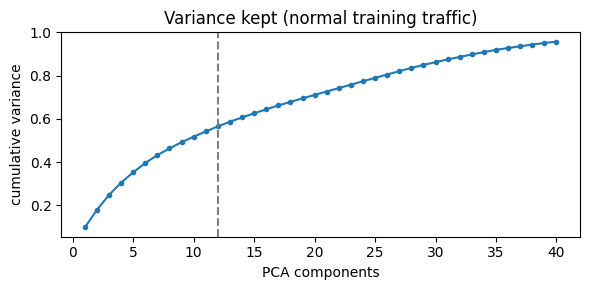

In [5]:
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore").fit(df[CATEGORICAL])

def tabular_features(frame):
    # 38 numeric + 84 one-hot = 122 features
    return np.hstack([frame[NUMERIC].to_numpy(float), ohe.transform(frame[CATEGORICAL])])

X_tr, X_val, X_te = (tabular_features(f) for f in (train, val, test))
raw_scaler = StandardScaler().fit(X_tr[is_normal_train])
X_tr, X_val, X_te = (raw_scaler.transform(x) for x in (X_tr, X_val, X_te))
print("tabular feature matrix:", X_tr.shape)

pca_full = PCA(random_state=SEED).fit(X_tr[is_normal_train])
cum = np.cumsum(pca_full.explained_variance_ratio_)
pca = PCA(n_components=N_MODES, random_state=SEED).fit(X_tr[is_normal_train])
Z_tr, Z_val, Z_te = (pca.transform(x) for x in (X_tr, X_val, X_te))
print(f"variance kept by {N_MODES} components: {cum[N_MODES - 1]:.1%}  (4 components: {cum[3]:.1%})")

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(np.arange(1, 41), cum[:40], marker=".")
ax.axvline(N_MODES, color="grey", ls="--")
ax.set(xlabel="PCA components", ylabel="cumulative variance", title="Variance kept (normal training traffic)")
plt.tight_layout(); plt.show()

### Encoding the 12 numbers as phases

Each PCA value becomes the angle of a phase shifter. Two properties of phases matter here:

* **Phases are periodic.** An angle of 0 and an angle of 2π are the same physical setting. Mapping data onto the full range [0, 2π] would make the smallest and the largest value of a feature indistinguishable.
* **Anomalies sit in the tails.** Network features are heavy-tailed, and an unseen attack often produces values *outside* the range seen in training. Min-max scaling followed by clipping maps all of them onto the boundary and erases the very signal a detector needs.

The next cell measures the second point directly: the share of test connections with at least one PCA value outside the range spanned by the normal training rows.

In [6]:
lo, hi = Z_tr[is_normal_train].min(0), Z_tr[is_normal_train].max(0)
outside = ((Z_te < lo) | (Z_te > hi)).any(1)
display(pd.Series(outside).groupby(fam_test).mean().rename("share of rows a clip would flatten").round(3).to_frame())

,share of rows a clip would flatten
dos,0.750
normal,0.003
probe,0.217
r2l,0.004
u2r,0.000


We therefore use a smooth, monotonic squash into the open interval (0, π):

$$
\varphi_i = \frac{\pi}{2}\left(1 + \tanh\frac{z_i - \mu_i}{3\,\sigma_i}\right),
$$

where $\mu_i, \sigma_i$ are the mean and standard deviation of component $i$ over normal training rows.
About ±3σ of normal traffic uses most of the range. Values further out are compressed towards 0 or π instead of being cut off at a hard boundary, and they never wrap around. (Some DoS rows lie hundreds of σ away; in floating point those do reach 0 or π exactly, which is the graceful version of saturation.)

In [7]:
mu, sd = Z_tr[is_normal_train].mean(0), Z_tr[is_normal_train].std(0) + 1e-12

def to_phase(Z):
    return (np.pi / 2) * (1 + np.tanh((Z - mu) / (3 * sd)))

P_tr, P_val, P_te = (to_phase(z) for z in (Z_tr, Z_val, Z_te))
print("phase range on test rows:", P_te.min().round(4), "to", P_te.max().round(4))

phase range on test rows: 0.0 to 3.1416


## 2. Building the QORC

### Boson Sampling in one paragraph

Boson Sampling sends $n$ indistinguishable photons through an $m$-mode linear-optical interferometer and records how many photons leave in each output mode.
A *mode* is one optical path; an *occupation pattern* such as $|1,0,0,1,0,1\rangle$ lists the photon count per mode.
The interferometer is an $m \times m$ unitary matrix $U$. For input pattern $T$ and output pattern $S$, the ideal probability is

$$
P(S \mid T) = \frac{\left|\operatorname{Perm}(U_{S,T})\right|^2}{\prod_i s_i!\,\prod_j t_j!},
$$

where $U_{S,T}$ is the $n \times n$ submatrix with rows chosen by the output modes and columns by the input modes, and $\operatorname{Perm}$
is the matrix permanent (a determinant without the alternating signs). Computing permanents is hard in general, which is why
large Boson Sampling instances are believed to be hard to simulate classically. Our instance is deliberately small enough to simulate exactly.

### The reservoir circuit

Following Sakurai et al., the circuit is

$$
U(\boldsymbol{\varphi}) = U_{\text{res}}\; D(\boldsymbol{\varphi})\; U_{\text{res}}, \qquad D(\boldsymbol{\varphi}) = \operatorname{diag}\left(e^{i\varphi_1}, \dots, e^{i\varphi_{12}}\right),
$$

* $U_{\text{res}}$ is a **Haar-random** $12 \times 12$ unitary, drawn once from a seed and then frozen. It is the reservoir and is never trained.
* $D(\boldsymbol\varphi)$ is a column of 12 phase shifters, the "dials", set by the data.
* **Input**: 3 photons spread over the modes, $T = |1,0,0,0,0,0,1,0,0,0,0,1\rangle$ (modes 0, 6 and 11).
* **Readout**: we keep the $\binom{12}{3} = 220$ outputs with at most one photon per mode (*no-bunching*; this matches threshold detectors, which only say whether a mode clicked) and renormalise them.

The data enter only as phases, yet the output probabilities depend on them **nonlinearly**: each amplitude is a permanent,
a degree-3 polynomial in $e^{i\varphi_j}$, and the probability is its squared modulus. These 220 numbers are the reservoir features.

Perceval builds and simulates this circuit:

input state: [1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1] | readout dimension: 220


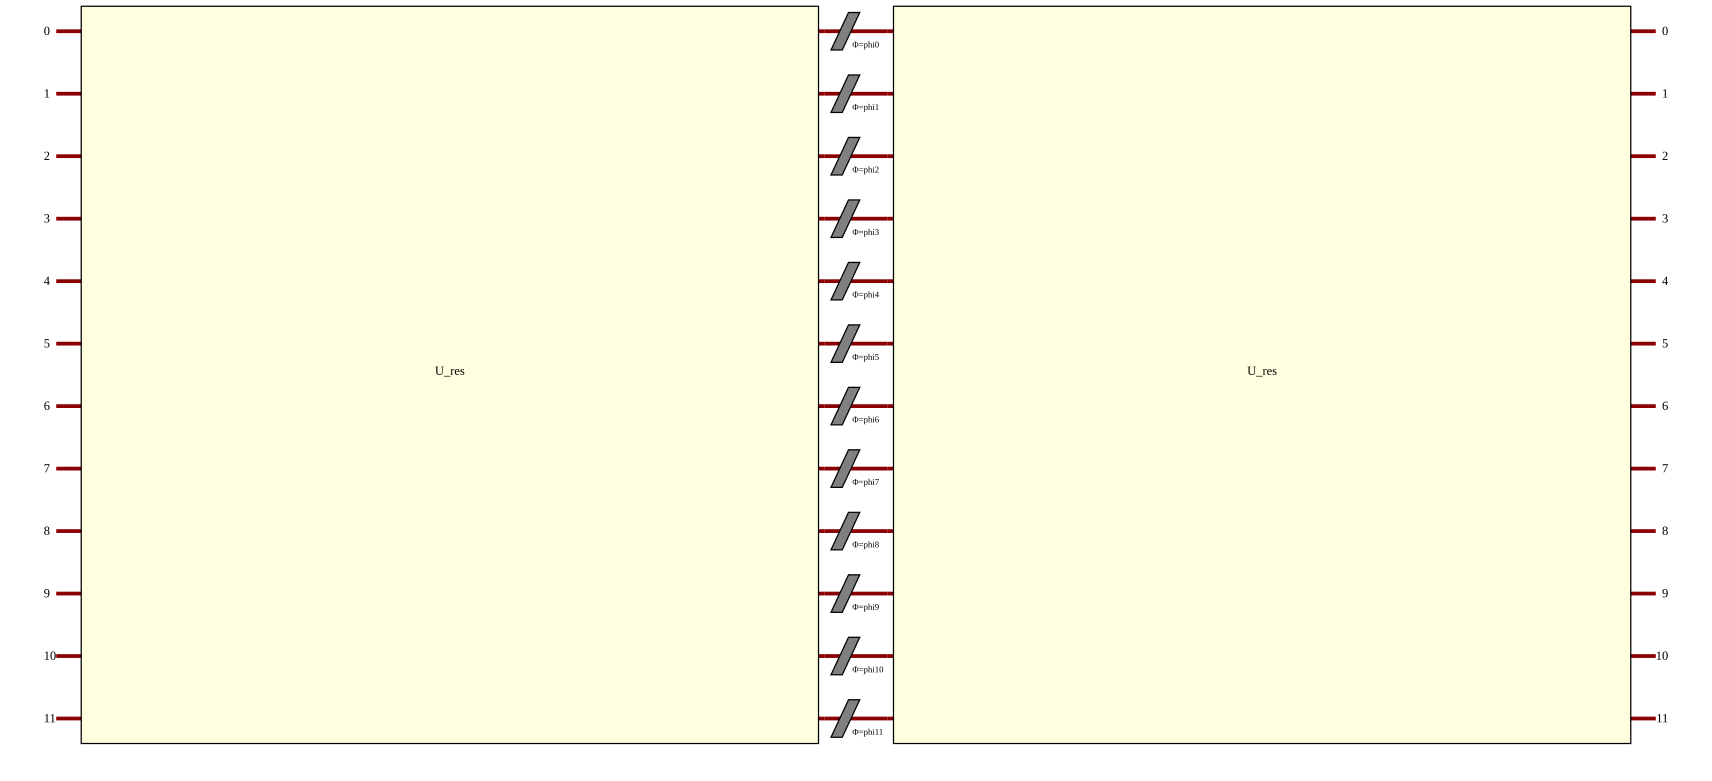

In [8]:
INPUT_STATE = [0] * N_MODES
for k in range(N_PHOTONS):                       # spread photons evenly: modes 0, 6, 11
    INPUT_STATE[round(k * (N_MODES - 1) / (N_PHOTONS - 1))] = 1
INPUT_MODES = [i for i, v in enumerate(INPUT_STATE) if v]
# Fixed ordering of the 220 no-bunching output patterns, shared by every row and every split
OUTPUTS = list(itertools.combinations(range(N_MODES), N_PHOTONS))
print("input state:", INPUT_STATE, "| readout dimension:", len(OUTPUTS))

def build_reservoir(seed):
    # Haar-random unitary from a seeded generator (QR of a complex Gaussian matrix)
    rng = np.random.default_rng(seed)
    G = (rng.standard_normal((N_MODES, N_MODES)) + 1j * rng.standard_normal((N_MODES, N_MODES))) / np.sqrt(2)
    Q, R = np.linalg.qr(G)
    return Q * (np.diag(R) / np.abs(np.diag(R)))

def perceval_circuit(U):
    phi = [pcvl.P(f"phi{i}") for i in range(N_MODES)]
    c = pcvl.Circuit(N_MODES, name="QORC")
    c.add(0, pcvl.Unitary(pcvl.Matrix(U), name="U_res"))
    for i in range(N_MODES):
        c.add(i, pcvl.PS(phi[i]))
    c.add(0, pcvl.Unitary(pcvl.Matrix(U), name="U_res"))
    return c, phi

U_res = build_reservoir(SEED)
circuit, phi = perceval_circuit(U_res)
pcvl.pdisplay(circuit)

In [9]:
sim = Simulator(SLOSBackend())
input_state = pcvl.BasicState(INPUT_STATE)
output_states = [pcvl.BasicState([1 if i in o else 0 for i in range(N_MODES)]) for o in OUTPUTS]

def perceval_features(phases):
    # One row of phases -> 220 renormalised no-bunching probabilities, with Perceval's SLOS backend
    for p, v in zip(phi, phases):
        p.set_value(float(v))
    sim.set_circuit(circuit)
    dist = sim.probs(input_state)
    f = np.array([dist.get(s, 0.0) for s in output_states])
    return f / f.sum(), f.sum()

f0, kept = perceval_features(P_tr[0])
print(f"first training row -> {f0.shape[0]} features; {kept:.1%} of the probability has no bunching")

first training row -> 220 features; 57.7% of the probability has no bunching


### A faster, equivalent implementation

SLOS takes a few milliseconds per row, which is fine for one row but slow for ~13,000 rows × 3 seeds.
Because the circuit is small, we can evaluate the permanent formula above directly with NumPy for all rows at once:
$U(\boldsymbol\varphi) = U_{\text{res}} D(\boldsymbol\varphi) U_{\text{res}}$, select the input columns, and for each of the 220 output
triples sum the 3! = 6 products that make up a 3 × 3 permanent. The next cell checks that both implementations agree.

In [10]:
PERMS = list(itertools.permutations(range(N_PHOTONS)))
OUT_IDX = np.array(OUTPUTS)

def quantum_features(P, U, batch=4096):
    # (n_rows, 12) phases -> (n_rows, 220) renormalised no-bunching Fock probabilities
    out = []
    for i in range(0, len(P), batch):
        D = np.exp(1j * P[i:i + batch])                                  # (b, 12)
        W = np.einsum("ij,bj,jk->bik", U, D, U[:, INPUT_MODES])          # (b, 12, 3): input columns of U(phi)
        S = W[:, OUT_IDX, :]                                             # (b, 220, 3, 3) submatrices U_{S,T}
        perm = sum(np.prod([S[:, :, r, p[r]] for r in range(N_PHOTONS)], axis=0) for p in PERMS)
        prob = np.abs(perm) ** 2
        out.append(prob / prob.sum(1, keepdims=True))
    return np.vstack(out)

check_rows = P_te[:20]
ref = np.array([perceval_features(r)[0] for r in check_rows])
diff = np.abs(quantum_features(check_rows, U_res) - ref).max()
print(f"max |NumPy - Perceval| over 20 rows x 220 features: {diff:.2e}")
assert diff < 1e-9

max |NumPy - Perceval| over 20 rows x 220 features: 7.63e-17


Two properties of this feature map are worth knowing before reading any result:

* **Only 11 of the 12 phases carry information.** Adding the same angle $c$ to every dial multiplies $U(\boldsymbol\varphi)$ by a global phase $e^{ic}$, and every probability is unchanged. Only the 11 phase *differences* matter. With 12 modes this costs one dimension out of twelve; on a 4-mode circuit it would cost a quarter of the input.
* **These are exact probabilities.** A physical device would estimate each of the 220 numbers from a finite number of detection events (shots), which adds sampling noise, and would add photon loss and detector imperfections. The simulation shows what the feature map can do in the ideal case; it says nothing yet about quantum advantage.

In [11]:
shift = quantum_features(P_te[:5] + 0.7, U_res) - quantum_features(P_te[:5], U_res)
print(f"change after adding 0.7 rad to every phase: {np.abs(shift).max():.1e}")

t0 = time.time()
Q_tr, Q_val, Q_te = (quantum_features(p, U_res) for p in (P_tr, P_val, P_te))
print(f"reservoir features: train {Q_tr.shape}, val {Q_val.shape}, test {Q_te.shape} in {time.time() - t0:.1f}s")

change after adding 0.7 rad to every phase: 5.6e-17


reservoir features: train (6500, 220), val (1000, 220), test (7047, 220) in 1.6s


## 3. Training process

### The rule that makes the comparison fair

A good score for the reservoir features does not, by itself, show that the reservoir did anything useful: the 12 phases already
contain most of the information. So every classical head below is trained, with identical settings, on four **feature views**:

| view | dimension | what it tests |
|---|---|---|
| `quantum` | 220 | the QORC output |
| `dials` | 12 | the PCA values that enter the reservoir: did the reservoir add anything to its own input? |
| `rff` | 220 | random Fourier features of the dials: a *classical* random nonlinear lift of the same width |
| `raw` | 122 | all scaled tabular features, no compression |

The reservoir earns credit only when `quantum` beats `dials` under the same head, and it is *quantum-specific* only if it also beats `rff`.

Each view is standardised with statistics from the normal training rows.

In [12]:
def rff_features(Z_list, seed, dim=len(OUTPUTS)):
    # Random Fourier features of the standardised dials; bandwidth by the median heuristic (untuned, like the reservoir)
    sc = StandardScaler().fit(Z_list[0])
    Zs = [sc.transform(z) for z in Z_list]
    rng = np.random.default_rng(seed + 10_000)
    sample = Zs[0][rng.choice(len(Zs[0]), size=2000, replace=False)]
    d2 = ((sample[:, None, :] - sample[None, :, :]) ** 2).sum(-1)
    sigma = np.sqrt(np.median(d2[d2 > 0]))
    W = rng.standard_normal((Zs[0].shape[1], dim)) / sigma
    b = rng.uniform(0, 2 * np.pi, dim)
    return [np.sqrt(2 / dim) * np.cos(z @ W + b) for z in Zs]

def make_views(seed):
    # All four feature views for one reservoir/RFF seed, standardised on normal training rows
    U = build_reservoir(seed)
    views = {
        "quantum": [quantum_features(p, U) for p in (P_tr, P_val, P_te)],
        "dials": [Z_tr, Z_val, Z_te],
        "rff": rff_features([Z_tr[is_normal_train], Z_tr, Z_val, Z_te], seed)[1:],
        "raw": [X_tr, X_val, X_te],
    }
    out = {}
    for name, (a, b, c) in views.items():
        sc = StandardScaler().fit(a[is_normal_train])
        out[name] = tuple(sc.transform(x) for x in (a, b, c))
    return out

views = make_views(SEED)
print({k: v[0].shape[1] for k, v in views.items()})

{'quantum': 220, 'dials': 12, 'rff': 220, 'raw': 122}


### Two ways to decide that a connection is an attack

**Supervised readout.** A logistic regression is trained on normal *and* DoS rows and flags a connection when its attack probability exceeds 0.5.
It learns the boundary between normal traffic and the attacks it has seen. Nothing in its objective asks it to recognise attacks that look unlike DoS.

**Novelty detection.** The detector is trained on the 4,000 **normal** training rows only and learns what normal traffic looks like; anything far from it is suspicious.
No attack is ever shown to it, so every attack family is unseen. We use two detectors:

* an **autoencoder** (a small neural network, hidden layers 128-8-128) that learns to compress and reconstruct normal rows; the anomaly score is the reconstruction error;
* a **linear detector**: PCA with 8 components fitted on normal rows; the score is the reconstruction error. It is the linear counterpart of the autoencoder and the cheapest possible head;
* an **Isolation Forest** (300 trees), a standard tree-based anomaly detector.

Each detector raises an alarm when its score exceeds the 99th percentile of scores on the **normal validation rows**, i.e. a 1% false-alarm budget.
In operations this is the number that matters: on a link with a million normal connections per day, a 1% budget already means 10,000 alerts.

In [13]:
def fit_supervised(view, seed):
    Xa, _, Xc = view
    clf = LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000, random_state=seed).fit(Xa, y_train)
    score = clf.predict_proba(Xc)[:, 1]
    return score, (score >= 0.5).astype(int)

def fit_novelty(view, kind, seed):
    Xa, Xb, Xc = view
    Xn = Xa[is_normal_train]                                   # normal traffic only
    if kind == "autoencoder":
        ae = MLPRegressor(hidden_layer_sizes=(128, 8, 128), alpha=1e-4, learning_rate_init=1e-3, max_iter=300,
                          early_stopping=True, random_state=seed).fit(Xn, Xn)
        score_fn = lambda X: ((ae.predict(X) - X) ** 2).mean(1)
    elif kind == "linear PCA-8":
        lin = PCA(n_components=8, random_state=seed).fit(Xn)
        score_fn = lambda X: ((lin.inverse_transform(lin.transform(X)) - X) ** 2).mean(1)
    else:
        iso = IsolationForest(n_estimators=300, random_state=seed).fit(Xn)
        score_fn = lambda X: -iso.score_samples(X)
    threshold = np.quantile(score_fn(Xb), 1 - FA_BUDGET)        # set on normal validation rows
    score = score_fn(Xc)
    return score, (score > threshold).astype(int)

def evaluate(score, pred):
    # Pooled AUC, mean of per-family AUCs, detection per family, and realised false-alarm rate
    normal = fam_test == "normal"
    row = {"AUC": roc_auc_score(y_test, score)}
    fam_auc = []
    for f in ["dos", "probe", "r2l", "u2r"]:
        m = normal | (fam_test == f)
        fam_auc.append(roc_auc_score(fam_test[m] != "normal", score[m]))
        row[f"det {f}"] = pred[fam_test == f].mean()
    row["macro AUC"] = np.mean(fam_auc)
    row["det all attacks"] = pred[~normal].mean()
    row["false alarms"] = pred[normal].mean()
    return row

In [14]:
t0 = time.time()
rows = []
for name, view in views.items():
    rows.append({"model": "logistic (normal + DoS)", "view": name, **evaluate(*fit_supervised(view, SEED))})
    for kind in ["autoencoder", "linear PCA-8", "isolation forest"]:
        rows.append({"model": f"{kind} (normal only)", "view": name, **evaluate(*fit_novelty(view, kind, SEED))})
res42 = pd.DataFrame(rows).set_index(["model", "view"])
print(f"trained {len(rows)} models in {time.time() - t0:.0f}s (seed {SEED})")
cols = ["AUC", "macro AUC", "det all attacks", "det dos", "det probe", "det r2l", "det u2r", "false alarms"]
display(res42[cols].round(3))

trained 16 models in 40s (seed 42)


,,AUC,macro AUC,det all attacks,det dos,det probe,det r2l,det u2r,false alarms
model,view,,,,,,,,
logistic (normal + DoS),quantum,0.852,0.699,0.593,0.997,0.574,0.037,0.115,0.005
autoencoder (normal only),quantum,0.961,0.952,0.592,0.943,0.525,0.163,0.577,0.009
linear PCA-8 (normal only),quantum,0.948,0.935,0.619,0.937,0.651,0.111,0.269,0.013
isolation forest (normal only),quantum,0.939,0.918,0.431,0.801,0.332,0.041,0.038,0.017
logistic (normal + DoS),dials,0.889,0.738,0.646,0.963,0.739,0.061,0.019,0.022
autoencoder (normal only),dials,0.959,0.950,0.613,0.953,0.626,0.082,0.577,0.007
linear PCA-8 (normal only),dials,0.853,0.839,0.314,0.743,0.046,0.083,0.058,0.012
isolation forest (normal only),dials,0.944,0.923,0.443,0.789,0.393,0.018,0.038,0.013
logistic (normal + DoS),rff,0.750,0.616,0.628,0.996,0.693,0.005,0.038,0.005


## 4. Comparison with classical baselines and conclusion

### Is the result stable?

A single random reservoir is one draw. We repeat the whole pipeline for three seeds; each seed draws a new reservoir unitary,
new random Fourier features and new model initialisations, while the data split stays fixed.

In [15]:
SEEDS = [42, 7, 123]
rows = []
t0 = time.time()
for seed in SEEDS:
    v = views if seed == SEED else make_views(seed)
    for name, view in v.items():
        rows.append({"seed": seed, "model": "logistic (normal + DoS)", "view": name, **evaluate(*fit_supervised(view, seed))})
        for kind in ["autoencoder", "linear PCA-8", "isolation forest"]:
            rows.append({"seed": seed, "model": f"{kind} (normal only)", "view": name,
                         **evaluate(*fit_novelty(view, kind, seed))})
allres = pd.DataFrame(rows)
print(f"{len(rows)} models over {len(SEEDS)} seeds in {time.time() - t0:.0f}s")

def mean_std(col):
    g = allres.groupby(["model", "view"], sort=False)[col]
    return g.mean().round(3).astype(str) + " ± " + g.std().round(3).astype(str)

summary = pd.DataFrame({c: mean_std(c) for c in ["macro AUC", "det all attacks", "det probe", "det r2l", "false alarms"]})
display(summary)

48 models over 3 seeds in 115s


,,macro AUC,det all attacks,det probe,det r2l,false alarms
model,view,,,,,
logistic (normal + DoS),quantum,0.633 ± 0.066,0.51 ± 0.073,0.365 ± 0.185,0.017 ± 0.017,0.005 ± 0.001
autoencoder (normal only),quantum,0.949 ± 0.003,0.589 ± 0.008,0.516 ± 0.015,0.163 ± 0.002,0.009 ± 0.001
linear PCA-8 (normal only),quantum,0.935 ± 0.005,0.511 ± 0.12,0.434 ± 0.252,0.101 ± 0.009,0.014 ± 0.005
isolation forest (normal only),quantum,0.918 ± 0.006,0.205 ± 0.196,0.198 ± 0.13,0.037 ± 0.034,0.013 ± 0.005
logistic (normal + DoS),dials,0.738 ± 0.0,0.646 ± 0.0,0.739 ± 0.0,0.061 ± 0.0,0.022 ± 0.0
autoencoder (normal only),dials,0.944 ± 0.01,0.632 ± 0.06,0.647 ± 0.153,0.136 ± 0.046,0.009 ± 0.002
linear PCA-8 (normal only),dials,0.839 ± 0.0,0.314 ± 0.0,0.046 ± 0.0,0.083 ± 0.0,0.012 ± 0.0
isolation forest (normal only),dials,0.922 ± 0.001,0.447 ± 0.012,0.4 ± 0.023,0.031 ± 0.014,0.013 ± 0.002
logistic (normal + DoS),rff,0.627 ± 0.011,0.552 ± 0.066,0.488 ± 0.18,0.006 ± 0.004,0.005 ± 0.0


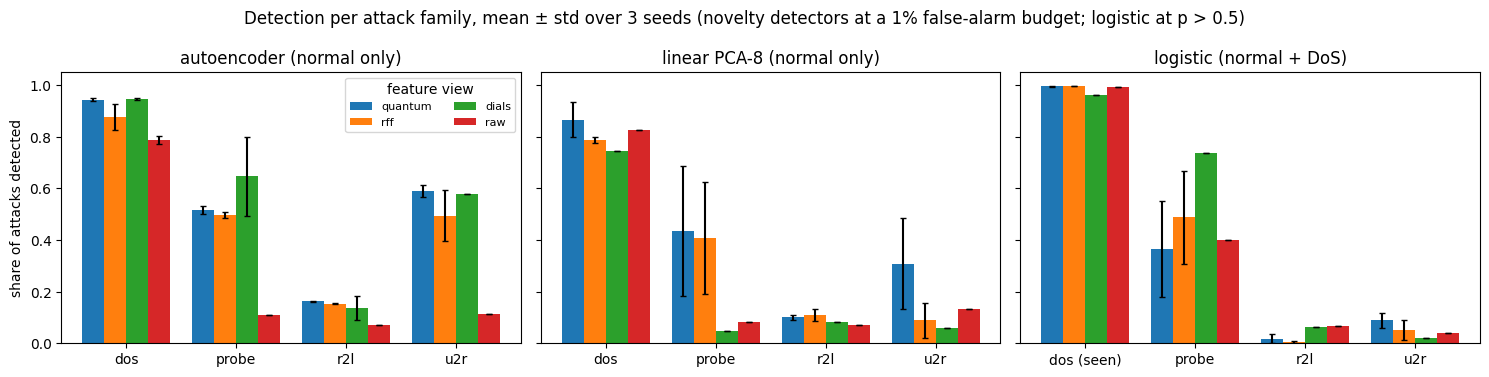

In [16]:
order = ["quantum", "rff", "dials", "raw"]
families = ["dos", "probe", "r2l", "u2r"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, model in zip(axes, ["autoencoder (normal only)", "linear PCA-8 (normal only)", "logistic (normal + DoS)"]):
    sub = allres[allres.model == model].groupby("view")[[f"det {f}" for f in families]]
    m, s = sub.mean().loc[order], sub.std().loc[order]
    x = np.arange(len(families))
    for k, view in enumerate(order):
        ax.bar(x + (k - 1.5) * 0.2, m.loc[view], 0.2, yerr=s.loc[view], label=view, capsize=2)
    ax.set_xticks(x, [f + (" (seen)" if f == "dos" and "logistic" in model else "") for f in families])
    ax.set_title(model); ax.set_ylim(0, 1.05)
axes[0].set_ylabel("share of attacks detected")
axes[0].legend(title="feature view", ncol=2, fontsize=8)
fig.suptitle("Detection per attack family, mean ± std over 3 seeds (novelty detectors at a 1% false-alarm budget; logistic at p > 0.5)")
plt.tight_layout(); plt.show()